<a href="https://colab.research.google.com/github/arjunk-15/Hospital-Emergency-Room-Analytics/blob/main/Hospital_ER_Analytics_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Hospital ER_Data.csv to Hospital ER_Data.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Hospital ER_Data.csv")
df.head()

,Patient Id,Patient Admission Date,Patient First Inital,Patient Last Name,Patient Gender,Patient Age,Patient Race,Department Referral,Patient Admission Flag,Patient Satisfaction Score,Patient Waittime,Patients CM
0,145-39-5406,20-03-2024 08:47,H,Glasspool,M,69,White,NaN,False,10.0,39,0
1,316-34-3057,15-06-2024 11:29,X,Methuen,M,4,Native American/Alaska Native,NaN,True,NaN,27,0
2,897-46-3852,20-06-2024 09:13,P,Schubuser,F,56,African American,General Practice,True,9.0,55,0
3,358-31-9711,04-02-2024 22:34,U,Titcombe,F,24,Native American/Alaska Native,General Practice,True,8.0,31,0
4,289-26-0537,04-09-2024 17:48,Y,Gionettitti,M,5,African American,Orthopedics,False,NaN,10,0


In [4]:
df.shape

(9216, 12)

In [5]:
df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)
print("Total Duplicate Records:", df.duplicated().sum())

Patient Id                     0.000000
Patient Admission Date         0.000000
Patient First Inital           0.000000
Patient Last Name              0.000000
Patient Gender                 0.000000
Patient Age                    0.000000
Patient Race                   0.000000
Department Referral           58.593750
Patient Admission Flag         0.000000
Patient Satisfaction Score    72.688802
Patient Waittime               0.000000
Patients CM                    0.000000
dtype: float64
Total Duplicate Records: 0


In [6]:
df.dtypes

,0
Patient Id,object
Patient Admission Date,object
Patient First Inital,object
Patient Last Name,object
Patient Gender,object
Patient Age,int64
Patient Race,object
Department Referral,object
Patient Admission Flag,bool
Patient Satisfaction Score,float64


In [7]:
df["Patient Admission Date"] = pd.to_datetime(
    df["Patient Admission Date"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

df["Patient Admission Date"].dtype

dtype('<M8[ns]')

In [8]:
df["Department Referral"].value_counts(dropna=False)

,count
Department Referral,
NaN,5400
General Practice,1840
Orthopedics,995
Physiotherapy,276
Cardiology,248
Neurology,193
Gastroenterology,178
Renal,86


In [9]:
df["Department Referral"] = df["Department Referral"].fillna("No Referral")
df.isnull().sum()

,0
Patient Id,0
Patient Admission Date,0
Patient First Inital,0
Patient Last Name,0
Patient Gender,0
Patient Age,0
Patient Race,0
Department Referral,0
Patient Admission Flag,0
Patient Satisfaction Score,6699


In [10]:
print("Gender:")
print(df["Patient Gender"].unique())

print("\nAdmission Status:")
print(df["Patient Admission Flag"].unique())

print("\nDepartment Referral:")
print(df["Department Referral"].unique())

Gender:
['M' 'F' 'NC']

Admission Status:
[False  True]

Department Referral:
['No Referral' 'General Practice' 'Orthopedics' 'Gastroenterology'
 'Physiotherapy' 'Neurology' 'Cardiology' 'Renal']


In [11]:
print("Minimum Age:", df["Patient Age"].min())
print("Maximum Age:", df["Patient Age"].max())

Minimum Age: 1
Maximum Age: 79


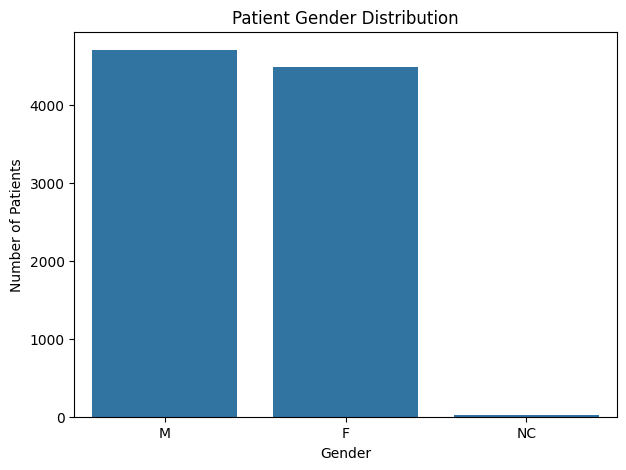

In [18]:
gender_counts = df["Patient Gender"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values
)

plt.title("Patient Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

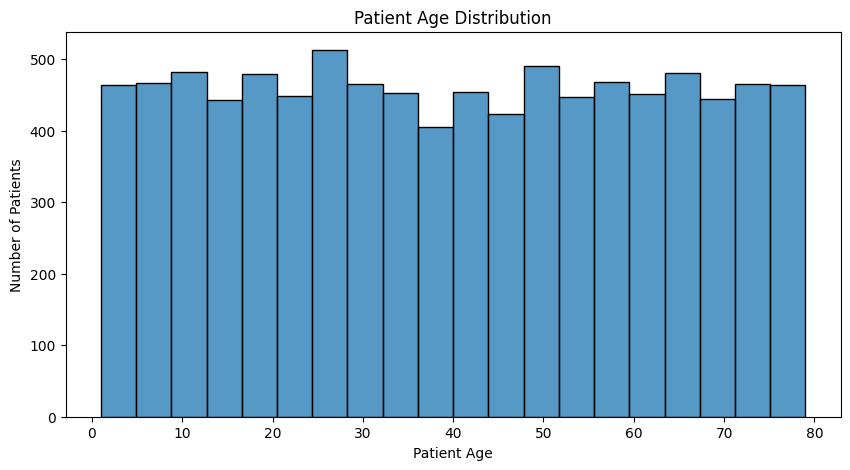

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Patient Age",
    bins=20,
)

plt.title("Patient Age Distribution")
plt.xlabel("Patient Age")
plt.ylabel("Number of Patients")

plt.show()

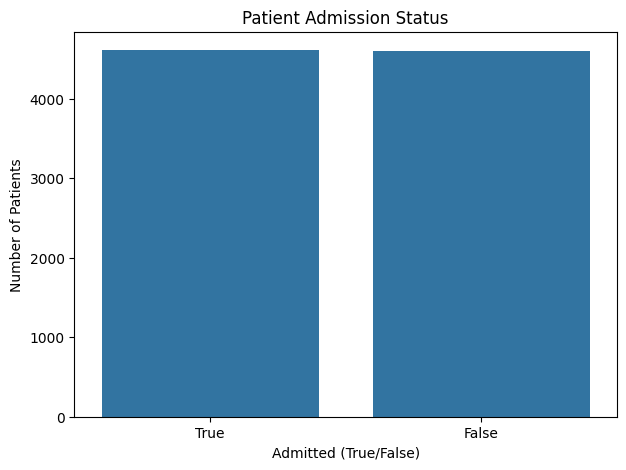

In [26]:
admission_counts = df["Patient Admission Flag"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=admission_counts.index.astype(str),
    y=admission_counts.values
)

plt.title("Patient Admission Status")
plt.xlabel("Admitted (True/False)")
plt.ylabel("Number of Patients")

plt.show()

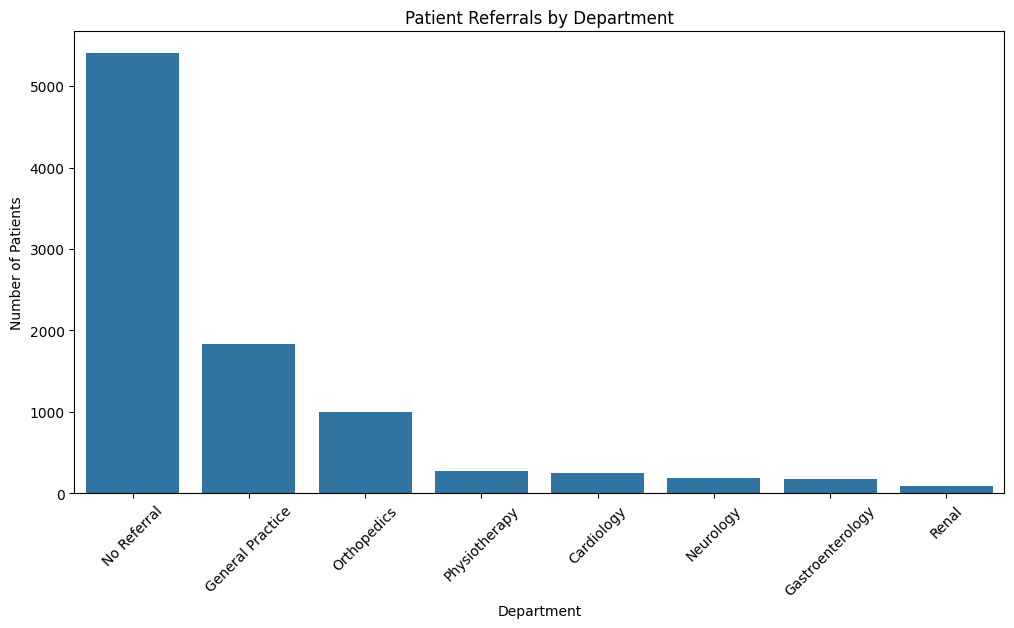

In [27]:
department_counts = df["Department Referral"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=department_counts.index,
    y=department_counts.values
)

plt.title("Patient Referrals by Department")
plt.xlabel("Department")
plt.ylabel("Number of Patients")

plt.xticks(rotation=45)

plt.show()

In [29]:
print("Average Waiting Time:",
      df["Patient Waittime"].mean())

print("Median Waiting Time:",
      df["Patient Waittime"].median())

print("Maximum Waiting Time:",
      df["Patient Waittime"].max())

print("Minimum Waiting Time:",
      df["Patient Waittime"].min())

Average Waiting Time: 35.25987413194444
Median Waiting Time: 35.0
Maximum Waiting Time: 60
Minimum Waiting Time: 10


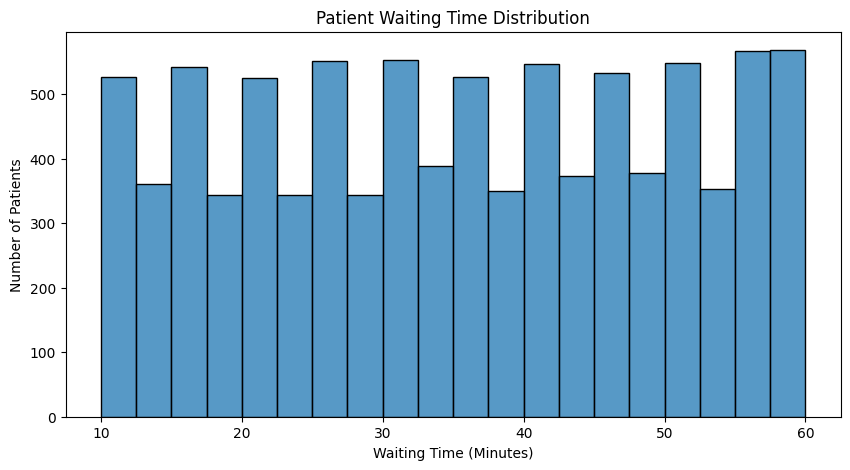

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Patient Waittime",
    bins=20,
)

plt.title("Patient Waiting Time Distribution")
plt.xlabel("Waiting Time (Minutes)")
plt.ylabel("Number of Patients")

plt.show()

Admission Counts:
Patient Admission Flag
True     4612
False    4604
Name: count, dtype: int64

Admission Percentage:
Patient Admission Flag
True     50.04
False    49.96
Name: proportion, dtype: float64


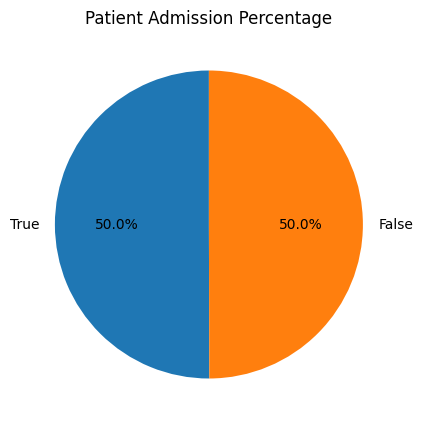

In [34]:
admission_counts = df["Patient Admission Flag"].value_counts()

admission_percentage = (
    df["Patient Admission Flag"].value_counts(normalize=True) * 100
)

print("Admission Counts:")
print(admission_counts)

print("\nAdmission Percentage:")
print(admission_percentage.round(2))

plt.figure(figsize=(7, 5))

plt.pie(
    admission_counts,
    labels=admission_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Patient Admission Percentage")

plt.show()

Available Satisfaction Scores: 2517
Average Satisfaction Score: 4.992054032578467
Median Satisfaction Score: 5.0


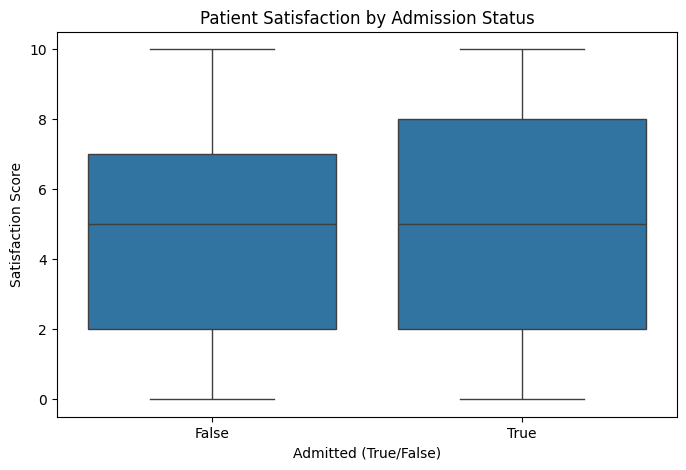

In [36]:
print("Available Satisfaction Scores:",
      df["Patient Satisfaction Score"].count())

print("Average Satisfaction Score:",
      df["Patient Satisfaction Score"].mean())

print("Median Satisfaction Score:",
      df["Patient Satisfaction Score"].median())

satisfaction_by_admission = (
    df.groupby("Patient Admission Flag")[
        "Patient Satisfaction Score"
    ].mean()
)

satisfaction_by_admission

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Patient Admission Flag",
    y="Patient Satisfaction Score"
)

plt.title("Patient Satisfaction by Admission Status")
plt.xlabel("Admitted (True/False)")
plt.ylabel("Satisfaction Score")

plt.show()

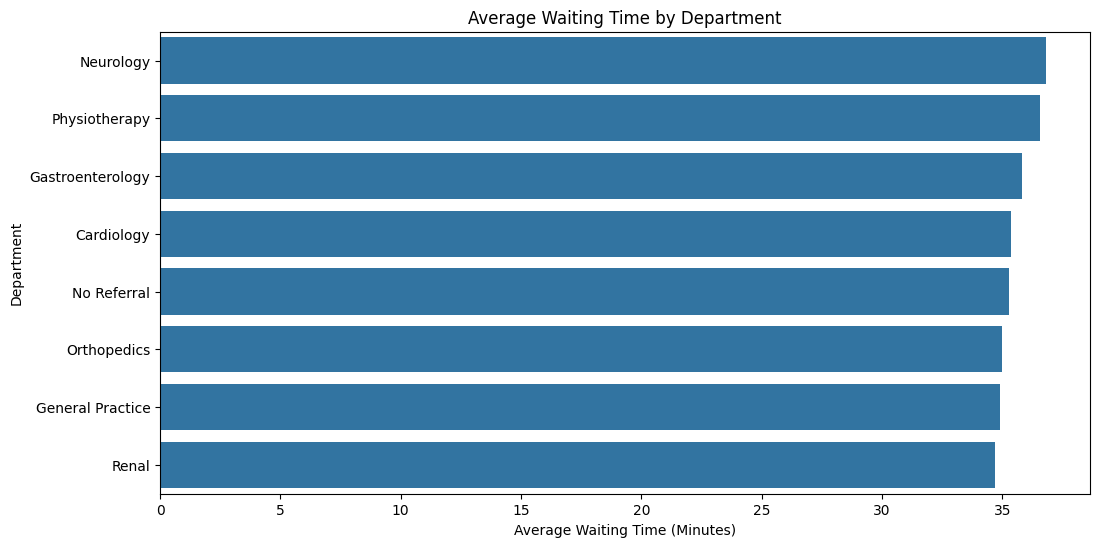

In [38]:
department_waittime = (
    df.groupby("Department Referral")["Patient Waittime"]
    .mean()
    .sort_values(ascending=False)
)

department_waittime

plt.figure(figsize=(12, 6))

sns.barplot(
    x=department_waittime.values,
    y=department_waittime.index
)

plt.title("Average Waiting Time by Department")
plt.xlabel("Average Waiting Time (Minutes)")
plt.ylabel("Department")

plt.show()

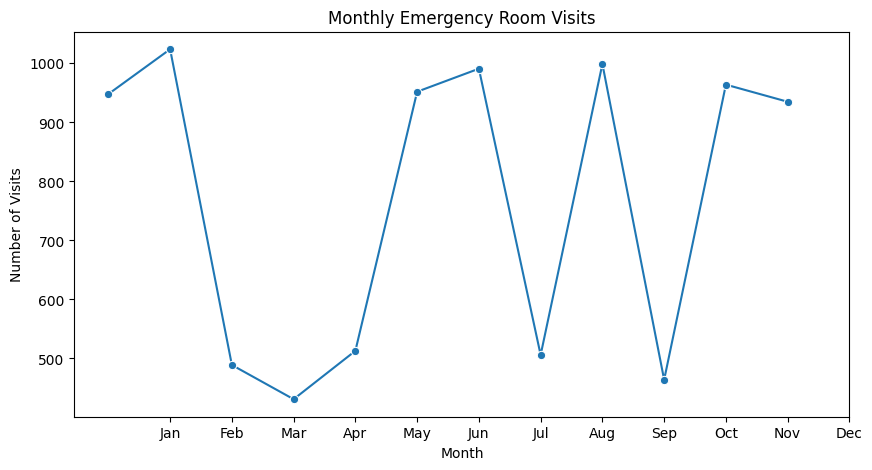

In [42]:
df["Admission Month"] = (
    df["Patient Admission Date"].dt.month_name()
)

monthly_visits = df["Admission Month"].value_counts().sort_index()

monthly_visits

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_visits.index,
    y=monthly_visits.values,
    marker="o"
)

plt.title("Monthly Emergency Room Visits")
plt.xlabel("Month")
plt.ylabel("Number of Visits")

plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

plt.show()

In [43]:
# Hospital KPI Summary

total_visits = len(df)

admission_rate = (
    df["Patient Admission Flag"].mean() * 100
)

average_waittime = df["Patient Waittime"].mean()

average_age = df["Patient Age"].mean()

average_satisfaction = (
    df["Patient Satisfaction Score"].mean()
)

most_referred_department = (
    df["Department Referral"].value_counts().idxmax()
)

print("Total Patient Visits:", total_visits)

print("Admission Rate:", round(admission_rate, 2), "%")

print("Average Waiting Time:",
      round(average_waittime, 2), "minutes")

print("Average Patient Age:",
      round(average_age, 2))

print("Average Satisfaction Score:",
      round(average_satisfaction, 2))

print("Most Common Department Referral:",
      most_referred_department)

Total Patient Visits: 9216
Admission Rate: 50.04 %
Average Waiting Time: 35.26 minutes
Average Patient Age: 39.86
Average Satisfaction Score: 4.99
Most Common Department Referral: No Referral


In [44]:
insights = pd.DataFrame({
    "KPI": [
        "Total Patient Visits",
        "Admission Rate (%)",
        "Average Waiting Time (Minutes)",
        "Average Patient Age",
        "Average Satisfaction Score"
    ],
    "Value": [
        total_visits,
        round(admission_rate, 2),
        round(average_waittime, 2),
        round(average_age, 2),
        round(average_satisfaction, 2)
    ]
})

insights

,KPI,Value
0,Total Patient Visits,9216.00
1,Admission Rate (%),50.04
2,Average Waiting Time (Minutes),35.26
3,Average Patient Age,39.86
4,Average Satisfaction Score,4.99


In [45]:
df.to_csv(
    "Hospital_ER_Cleaned.csv",
    index=False
)

files.download("Hospital_ER_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>